# Stage 2 :Trivial benchmark and classical baseline (RF + XGBoost)





## 0. Setup, paths and seeds
Same project folder as Stage 1. `SEEDS` are the three seeds used for the final runs of each model.

In [ ]:
import os, sys, json, time, random, hashlib, pickle, re, warnings
from pathlib import Path

SEED = 42
SEEDS = [42, 43, 44]
random.seed(SEED)

import numpy as np
np.random.seed(SEED)

IN_COLAB = "google.colab" in sys.modules
if os.environ.get("FORESTNET_BASE"):                      # only used for offline testing
    BASE = Path(os.environ["FORESTNET_BASE"])
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/forestnet_project")
elif Path("/kaggle/working").exists():
    BASE = Path("/kaggle/working/forestnet_project")
else:
    BASE = Path("./forestnet_project")

OUT_DIR = BASE / "outputs" / "stage2"
OUT_DIR.mkdir(parents=True, exist_ok=True)
LOG_PATH = BASE / "experiment_log.csv"
print("Project folder:", BASE)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/forestnet_project


In [ ]:
# xgboost and scikit-image are preinstalled on Colab; this line only installs them if missing.
!pip -q install xgboost scikit-image

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import sklearn, xgboost
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, recall_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import ParameterGrid, ParameterSampler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.inspection import permutation_importance
from skimage.feature import graycomatrix, graycoprops
from scipy.stats import loguniform, uniform, randint
from joblib import Parallel, delayed
import joblib
import skimage

warnings.filterwarnings("ignore", message="Unpickling a shapely")
print("sklearn", sklearn.__version__, "| xgboost", xgboost.__version__, "| skimage", skimage.__version__)

sklearn 1.6.1 | xgboost 3.4.1 | skimage 0.25.2


## 1. Load the frozen split and check it is unchanged


In [ ]:
def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

meta = json.load(open(BASE / "outputs" / "dataset_meta.json"))
manifest_path = BASE / "outputs" / "split_manifest.csv"
assert sha256(manifest_path) == meta["manifest_sha256"], "Manifest hash mismatch — the split has changed!"
man = pd.read_csv(manifest_path)
print("Manifest OK:", meta["manifest_sha256"][:12], "| split decision:", meta["split_decision"])

# Dataset root = the folder that contains train.csv (same search as Stage 1)
ROOT = next((BASE / "data" / "raw").rglob("train.csv")).parent
print("Dataset root:", ROOT)

CLASSES = sorted(man["merged_label"].unique())               # fixed alphabetical order
CLS2ID = {c: i for i, c in enumerate(CLASSES)}
man["y"] = man["merged_label"].map(CLS2ID)
P_ID, S_ID, O_ID, G_ID = (CLS2ID["Plantation"], CLS2ID["Smallholder agriculture"],
                          CLS2ID["Other"], CLS2ID["Grassland shrubland"])
print("Class ids:", CLS2ID)
print(man["split"].value_counts().to_dict())

Manifest OK: c51228bf421e | split decision: official
Dataset root: /content/drive/MyDrive/forestnet_project/data/raw/deep/downloads/ForestNetDataset
Class ids: {'Grassland shrubland': 0, 'Other': 1, 'Plantation': 2, 'Smallholder agriculture': 3}
{'train': 1616, 'test': 668, 'val': 473}


## 2. Metrics used for every model
- **macro-F1** (primary): F1 per class, then averaged, so each class counts equally.
- **recall Plantation / recall Other**: share of true Plantation / Other events that were found.
- **P→S rate**: share of true Plantation predicted as Smallholder (the most costly error).
- **O→S/G rate**: share of true Other predicted as Smallholder or Grassland (the next most costly).

In [ ]:
def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rec = recall_score(y_true, y_pred, labels=range(len(CLASSES)), average=None, zero_division=0)
    p_mask, o_mask = y_true == P_ID, y_true == O_ID
    return {
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "recall_plantation": rec[P_ID],
        "recall_other": rec[O_ID],
        "recall_smallholder": rec[S_ID],
        "recall_grassland": rec[G_ID],
        "rate_P_to_S": float((y_pred[p_mask] == S_ID).mean()),
        "rate_O_to_SG": float(np.isin(y_pred[o_mask], [S_ID, G_ID]).mean()),
    }

## 3. Experiment log helper
Appends one row per run to the shared `experiment_log.csv` created in Stage 1 (failures included).

In [ ]:
LOG_COLS = ["run_id", "date", "stage", "model", "change", "hyperparameters", "seed",
            "val_macro_f1", "val_recall_plantation", "val_recall_other",
            "train_time_s", "infer_ms_per_img", "outcome", "note"]

def log_run(run_id, model, change, params, seed, metrics=None, train_s=None, infer_ms=None,
            outcome="ok", note=""):
    m = metrics or {}
    row = {"run_id": run_id, "date": time.strftime("%Y-%m-%d %H:%M"), "stage": "2", "model": model,
           "change": change, "hyperparameters": json.dumps(params, default=str), "seed": seed,
           "val_macro_f1": round(m.get("macro_f1", np.nan), 4),
           "val_recall_plantation": round(m.get("recall_plantation", np.nan), 4),
           "val_recall_other": round(m.get("recall_other", np.nan), 4),
           "train_time_s": None if train_s is None else round(train_s, 2),
           "infer_ms_per_img": None if infer_ms is None else round(infer_ms, 4),
           "outcome": outcome, "note": note}
    pd.DataFrame([row], columns=LOG_COLS).to_csv(LOG_PATH, mode="a", header=not LOG_PATH.exists(), index=False)

## 4. Trivial benchmark - majority class
"No intelligence" floor: always predicts the most common training class (Plantation).

In [ ]:
tr, va = man[man.split == "train"], man[man.split == "val"]
dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(tr), 1)), tr["y"])
m_dummy = evaluate(va["y"], dummy.predict(np.zeros((len(va), 1))))
print({k: round(v, 4) for k, v in m_dummy.items()})
log_run("S2-DUMMY-001", "Majority class", "trivial benchmark", {"strategy": "most_frequent"}, SEED, m_dummy,
        note="floor for all models")

{'macro_f1': 0.1577, 'accuracy': 0.4609, 'recall_plantation': np.float64(1.0), 'recall_other': np.float64(0.0), 'recall_smallholder': np.float64(0.0), 'recall_grassland': np.float64(0.0), 'rate_P_to_S': 0.0, 'rate_O_to_SG': 0.0}


## 5. Infrared check : which channel is NIR, and is NDVI valid?
The infrared file has 3 channels. For Landsat 8 they are expected to be NIR, SWIR1, SWIR2, but the order is not documented.
Over vegetation, NIR is normally the **brightest** of the three. In this project also compare NIR and red value ranges:
NDVI = (NIR − Red) / (NIR + Red) is only meaningful if both are on the same scale.
**Expected if valid:** median NDVI of forest-dominated images clearly positive (roughly 0.3–0.9).


In [ ]:
rng = np.random.default_rng(SEED)
sample = tr.iloc[rng.choice(len(tr), size=min(60, len(tr)), replace=False)]
ch_means, red_vals, ir_vals = [], [], []
for p in sample["example_path"]:
    vis = np.array(Image.open(ROOT / p / "images" / "visible" / "composite.png").convert("RGB")).astype(np.float32)
    ir = np.load(ROOT / p / "images" / "infrared" / "composite.npy").astype(np.float32)
    ch_means.append(ir.reshape(-1, ir.shape[-1]).mean(0))
    red_vals.append(vis[..., 0].ravel()); ir_vals.append(ir.reshape(-1, ir.shape[-1]))
ch_means = np.array(ch_means)
red_vals = np.concatenate(red_vals); ir_vals = np.concatenate(ir_vals)
print("IR file shape/dtype:", ir.shape, ir.dtype)
print("Mean of each IR channel over sample:", ch_means.mean(0).round(2))
print("Red (visible) percentiles 1/50/99:", np.percentile(red_vals, [1, 50, 99]).round(1))
for c in range(ir_vals.shape[1]):
    print(f"IR channel {c} percentiles 1/50/99:", np.percentile(ir_vals[:, c], [1, 50, 99]).round(1))

NIR_CH = int(np.argmax(ch_means.mean(0)))        # brightest channel over vegetation
print("\n>>> Chosen NIR channel:", NIR_CH, "(brightest on average). Change NIR_CH manually if you disagree.")

def ndvi(vis_rgb, ir):
    red = vis_rgb[..., 0].astype(np.float32); nir = ir[..., NIR_CH].astype(np.float32)
    return (nir - red) / (nir + red + 1e-6)

nd_medians = [np.median(ndvi(np.array(Image.open(ROOT / p / "images" / "visible" / "composite.png").convert("RGB")),
                             np.load(ROOT / p / "images" / "infrared" / "composite.npy")))
              for p in sample["example_path"]]
print("Median NDVI per sampled image — percentiles 10/50/90:", np.percentile(nd_medians, [10, 50, 90]).round(3))

IR file shape/dtype: (332, 332, 3) float32
Mean of each IR channel over sample: [83.84 39.94 17.76]
Red (visible) percentiles 1/50/99: [ 5. 19. 72.]
IR channel 0 percentiles 1/50/99: [ 11.  86. 121.]
IR channel 1 percentiles 1/50/99: [ 4. 40. 73.]
IR channel 2 percentiles 1/50/99: [ 3. 16. 44.]

>>> Chosen NIR channel: 0 (brightest on average). Change NIR_CH manually if you disagree.
Median NDVI per sampled image — percentiles 10/50/90: [0.456 0.642 0.751]


## 6. Feature extraction (runs once, then cached)
Each composite becomes one row of numbers. Every feature is computed twice:
on the **whole image** (`w_`) and on a **central 64 × 64 crop** (`c_`, ≈ 0.96 km × 0.96 km).
Events are centred in their images, so the crop focuses on the loss area without using the polygon
(the model stays image-only).

| Group | Features | Why |
|---|---|---|
| Colour | mean, std, 10th/50th/90th percentile of R, G, B | Bare soil, crops, water and forest differ in colour |
| NDVI | mean, std, 10/50/90th percentile, share of pixels > 0.6 (dense vegetation) and < 0.2 (bare/cleared) | Vegetation amount and health |
| Texture (GLCM) | contrast, dissimilarity, homogeneity, energy, correlation, ASM at distances 1 and 3 (averaged over 4 directions) | Regular plantation grids vs patchy smallholder fields vs roads |

GLCM needs a grey image with few levels: each image is contrast-stretched (2nd–98th percentile, because composites are dark)
and quantised to 32 levels.

In [ ]:
CROP = 64
GLCM_LEVELS = 32
GLCM_DIST = [1, 3]
GLCM_ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
GLCM_PROPS = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]

def centre(a, size=CROP):
    h, w = a.shape[:2]; t, l = (h - size) // 2, (w - size) // 2
    return a[t:t + size, l:l + size]

def stats(x, name):
    x = x.ravel()
    q10, q50, q90 = np.percentile(x, [10, 50, 90])
    return {f"{name}_mean": x.mean(), f"{name}_std": x.std(), f"{name}_p10": q10, f"{name}_p50": q50, f"{name}_p90": q90}

def glcm_feats(gray, prefix):
    lo, hi = np.percentile(gray, [2, 98])
    q = np.clip((gray - lo) / (hi - lo + 1e-6), 0, 1)
    q = np.minimum((q * GLCM_LEVELS).astype(np.uint8), GLCM_LEVELS - 1)
    g = graycomatrix(q, distances=GLCM_DIST, angles=GLCM_ANGLES, levels=GLCM_LEVELS, symmetric=True, normed=True)
    out = {}
    for prop in GLCM_PROPS:
        vals = graycoprops(g, prop)                      # shape (n_dist, n_angles)
        for di, d in enumerate(GLCM_DIST):
            out[f"{prefix}_glcm_{prop}_d{d}"] = vals[di].mean()
    return out

def region_feats(vis, ir, prefix):
    f = {}
    v = vis.astype(np.float32) / 255.0
    for ci, cn in enumerate("RGB"):
        f.update(stats(v[..., ci], f"{prefix}_{cn}"))
    nd = ndvi(vis, ir)
    f.update(stats(nd, f"{prefix}_ndvi"))
    f[f"{prefix}_ndvi_gt06"] = float((nd > 0.6).mean())
    f[f"{prefix}_ndvi_lt02"] = float((nd < 0.2).mean())
    gray = 0.299 * v[..., 0] + 0.587 * v[..., 1] + 0.114 * v[..., 2]
    f.update(glcm_feats(gray, prefix))
    return f

def extract(path):
    try:
        vis = np.array(Image.open(ROOT / path / "images" / "visible" / "composite.png").convert("RGB"))
        ir = np.load(ROOT / path / "images" / "infrared" / "composite.npy")
        f = {"example_path": path}
        f.update(region_feats(vis, ir, "w"))
        f.update(region_feats(centre(vis), centre(ir), "c"))
        return f
    except Exception as e:                                # record failures instead of stopping
        return {"example_path": path, "error": repr(e)}

FEAT_PATH = OUT_DIR / f"features_nir{NIR_CH}_crop{CROP}.csv"
if FEAT_PATH.exists():
    feats = pd.read_csv(FEAT_PATH)
    print("Loaded cached features:", FEAT_PATH.name)
else:
    t0 = time.time()
    rows = Parallel(n_jobs=-1, verbose=5)(delayed(extract)(p) for p in man["example_path"])
    feats = pd.DataFrame(rows)
    print(f"Feature extraction took {time.time() - t0:.0f}s")
    if "error" in feats.columns and feats["error"].notna().any():
        print("FAILED images:", feats["error"].notna().sum()); display(feats[feats["error"].notna()].head())
    feats.to_csv(FEAT_PATH, index=False)

FEATURES = [c for c in feats.columns if c not in ("example_path", "error")]
print(len(FEATURES), "features")
data = man.merge(feats, on="example_path", how="left")
assert len(data) == len(man) and data[FEATURES].notna().all().all(), "Missing feature values — see failures above."

X_tr, y_tr = data.loc[data.split == "train", FEATURES].values, data.loc[data.split == "train", "y"].values
X_va, y_va = data.loc[data.split == "val", FEATURES].values, data.loc[data.split == "val", "y"].values
print("Train", X_tr.shape, "| Val", X_va.shape)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:   19.4s
[Parallel(n_jobs=-1)]: Done  68 tasks      | elapsed:  1.4min
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed:  3.2min
[Parallel(n_jobs=-1)]: Done 284 tasks      | elapsed:  5.6min
[Parallel(n_jobs=-1)]: Done 446 tasks      | elapsed:  8.7min
[Parallel(n_jobs=-1)]: Done 644 tasks      | elapsed: 12.6min
[Parallel(n_jobs=-1)]: Done 878 tasks      | elapsed: 17.2min
[Parallel(n_jobs=-1)]: Done 1148 tasks      | elapsed: 23.0min
[Parallel(n_jobs=-1)]: Done 1454 tasks      | elapsed: 28.9min
[Parallel(n_jobs=-1)]: Done 1796 tasks      | elapsed: 35.7min
[Parallel(n_jobs=-1)]: Done 2174 tasks      | elapsed: 43.1min
[Parallel(n_jobs=-1)]: Done 2588 tasks      | elapsed: 51.3min
[Parallel(n_jobs=-1)]: Done 2757 out of 2757 | elapsed: 54.6min finished


Feature extraction took 3274s
68 features
Train (1616, 68) | Val (473, 68)


In [ ]:
# Quick look (train only): do the features differ between classes?
show = ["w_R_mean", "w_G_mean", "w_ndvi_mean", "c_ndvi_lt02", "w_glcm_contrast_d1", "c_glcm_homogeneity_d1"]
display(data[data.split == "train"].groupby("merged_label")[show].mean().round(3))

## 7. Model training helper
Both models use **class weights** so the small classes (Other, Grassland) are not ignored:
- Random Forest: `class_weight="balanced"`.
- XGBoost: per-sample weights = inverse class frequency.

Trees do not need feature scaling. Each configuration is trained on **train**, scored on **val**.
Inference time is measured on the validation set (milliseconds per image, features already extracted).

In [ ]:
def make_model(kind, params, seed):
    if kind == "RF":
        return RandomForestClassifier(**params, class_weight="balanced", random_state=seed, n_jobs=-1)
    return XGBClassifier(**params, objective="multi:softprob", num_class=len(CLASSES), tree_method="hist",
                         eval_metric="mlogloss", random_state=seed, n_jobs=-1)

def fit_eval(kind, params, seed):
    model = make_model(kind, params, seed)
    t0 = time.time()
    if kind == "XGB":
        model.fit(X_tr, y_tr, sample_weight=compute_sample_weight("balanced", y_tr))
    else:
        model.fit(X_tr, y_tr)
    train_s = time.time() - t0
    t0 = time.time(); pred = model.predict(X_va); infer_ms = (time.time() - t0) * 1000 / len(X_va)
    return model, pred, evaluate(y_va, pred), train_s, infer_ms

def search(kind, configs, prefix):
    rows = []
    for i, params in enumerate(configs, 1):
        run_id = f"{prefix}-{i:03d}"
        try:
            _, _, m, ts, ims = fit_eval(kind, params, SEED)
            log_run(run_id, kind, "tuning", params, SEED, m, ts, ims)
            rows.append({"run_id": run_id, **params, **m, "train_s": ts, "infer_ms": ims})
            print(f"{run_id}  macro-F1 {m['macro_f1']:.4f}  ({ts:.1f}s)")
        except Exception as e:
            log_run(run_id, kind, "tuning", params, SEED, outcome="failed", note=repr(e)[:200])
            print(f"{run_id}  FAILED: {e!r}")
    return pd.DataFrame(rows)

## 8. Random Forest with  full grid (24 configurations)
| Hyperparameter | Values | What it controls |
|---|---|---|
| n_estimators | 200, 500 | number of trees |
| max_depth | None, 10, 20 | how complex each tree can get |
| max_features | "sqrt", 0.3 | features considered at each split (diversity of trees) |
| min_samples_leaf | 1, 3 | smallest group a leaf may hold (smoothing) |

In [ ]:
RF_GRID = {"n_estimators": [200, 500], "max_depth": [None, 10, 20],
           "max_features": ["sqrt", 0.3], "min_samples_leaf": [1, 3]}
rf_configs = list(ParameterGrid(RF_GRID))
assert len(rf_configs) == 24
rf_res = search("RF", rf_configs, "S2-RF")
rf_res.to_csv(OUT_DIR / "rf_search.csv", index=False)
display(rf_res.sort_values("macro_f1", ascending=False).head(5).round(4))

S2-RF-001  macro-F1 0.6494  (2.3s)
S2-RF-002  macro-F1 0.6377  (7.0s)
S2-RF-003  macro-F1 0.6648  (2.7s)
S2-RF-004  macro-F1 0.6780  (4.8s)
S2-RF-005  macro-F1 0.6370  (7.5s)
S2-RF-006  macro-F1 0.6429  (12.6s)
S2-RF-007  macro-F1 0.6618  (6.1s)
S2-RF-008  macro-F1 0.6776  (11.3s)
S2-RF-009  macro-F1 0.6559  (2.9s)
S2-RF-010  macro-F1 0.6589  (4.7s)
S2-RF-011  macro-F1 0.6664  (1.8s)
S2-RF-012  macro-F1 0.6724  (5.8s)
S2-RF-013  macro-F1 0.6555  (4.8s)
S2-RF-014  macro-F1 0.6703  (11.9s)
S2-RF-015  macro-F1 0.6711  (3.9s)
S2-RF-016  macro-F1 0.6661  (11.5s)
S2-RF-017  macro-F1 0.6405  (2.2s)
S2-RF-018  macro-F1 0.6372  (5.4s)
S2-RF-019  macro-F1 0.6648  (1.9s)
S2-RF-020  macro-F1 0.6780  (7.1s)
S2-RF-021  macro-F1 0.6349  (4.6s)
S2-RF-022  macro-F1 0.6372  (13.9s)
S2-RF-023  macro-F1 0.6635  (4.1s)
S2-RF-024  macro-F1 0.6788  (12.5s)


,run_id,max_depth,max_features,min_samples_leaf,n_estimators,macro_f1,accuracy,recall_plantation,recall_other,recall_smallholder,recall_grassland,rate_P_to_S,rate_O_to_SG,train_s,infer_ms
23,S2-RF-024,20.0,0.3,3,500,0.6788,0.7336,0.8349,0.5714,0.7429,0.4667,0.1101,0.2571,12.4657,0.2948
3,S2-RF-004,NaN,sqrt,3,500,0.6780,0.7357,0.8394,0.5857,0.7500,0.4222,0.1055,0.2429,4.8390,0.3138
19,S2-RF-020,20.0,sqrt,3,500,0.6780,0.7357,0.8394,0.5857,0.7500,0.4222,0.1055,0.2429,7.1352,0.2917
7,S2-RF-008,NaN,0.3,3,500,0.6776,0.7315,0.8303,0.5714,0.7429,0.4667,0.1147,0.2571,11.3265,0.2752
11,S2-RF-012,10.0,sqrt,3,500,0.6724,0.7188,0.8028,0.5714,0.7214,0.5333,0.1239,0.2429,5.7753,0.2790


## 9. XGBoost with random search (40 configurations)
Configurations are drawn from the ranges below with a fixed seed, so the same 40 are drawn on every re-run.
| Hyperparameter | Range | What it controls |
|---|---|---|
| n_estimators | 100–600 | number of boosting rounds |
| max_depth | 3–8 | tree complexity |
| learning_rate | 0.01–0.3 (log scale) | step size of each round |
| subsample | 0.6–1.0 | share of rows per tree |
| colsample_bytree | 0.5–1.0 | share of features per tree |
| min_child_weight | 1–10 | minimum evidence for a split |
| gamma | 0–2 | minimum loss reduction for a split |
| reg_lambda | 0.1–10 (log scale) | L2 regularisation |

In [ ]:
XGB_SPACE = {"n_estimators": randint(100, 601), "max_depth": randint(3, 9),
             "learning_rate": loguniform(0.01, 0.3), "subsample": uniform(0.6, 0.4),
             "colsample_bytree": uniform(0.5, 0.5), "min_child_weight": randint(1, 11),
             "gamma": uniform(0, 2), "reg_lambda": loguniform(0.1, 10)}
xgb_configs = [{k: (round(float(v), 5) if isinstance(v, float) else int(v)) for k, v in c.items()}
               for c in ParameterSampler(XGB_SPACE, n_iter=40, random_state=SEED)]
xgb_res = search("XGB", xgb_configs, "S2-XGB")
xgb_res.to_csv(OUT_DIR / "xgb_search.csv", index=False)
display(xgb_res.sort_values("macro_f1", ascending=False).head(5).round(4))

S2-XGB-001  macro-F1 0.6623  (1.4s)
S2-XGB-002  macro-F1 0.6586  (9.9s)
S2-XGB-003  macro-F1 0.6752  (2.0s)
S2-XGB-004  macro-F1 0.6862  (14.2s)
S2-XGB-005  macro-F1 0.6591  (1.7s)
S2-XGB-006  macro-F1 0.6884  (8.4s)
S2-XGB-007  macro-F1 0.6749  (1.8s)
S2-XGB-008  macro-F1 0.6841  (1.6s)
S2-XGB-009  macro-F1 0.6627  (2.1s)
S2-XGB-010  macro-F1 0.6714  (12.9s)
S2-XGB-011  macro-F1 0.6890  (1.5s)
S2-XGB-012  macro-F1 0.6726  (2.0s)
S2-XGB-013  macro-F1 0.6739  (5.6s)
S2-XGB-014  macro-F1 0.6697  (6.5s)
S2-XGB-015  macro-F1 0.6318  (1.1s)
S2-XGB-016  macro-F1 0.6747  (9.7s)
S2-XGB-017  macro-F1 0.6796  (12.6s)
S2-XGB-018  macro-F1 0.6822  (1.2s)
S2-XGB-019  macro-F1 0.6893  (2.6s)
S2-XGB-020  macro-F1 0.6786  (1.7s)
S2-XGB-021  macro-F1 0.6733  (2.1s)
S2-XGB-022  macro-F1 0.6874  (7.4s)
S2-XGB-023  macro-F1 0.6736  (1.8s)
S2-XGB-024  macro-F1 0.6604  (1.5s)
S2-XGB-025  macro-F1 0.6954  (3.5s)
S2-XGB-026  macro-F1 0.6955  (7.4s)
S2-XGB-027  macro-F1 0.6247  (1.4s)
S2-XGB-028  macro-F1 0.67

,run_id,colsample_bytree,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,subsample,macro_f1,accuracy,recall_plantation,recall_other,recall_smallholder,recall_grassland,rate_P_to_S,rate_O_to_SG,train_s,infer_ms
28,S2-XGB-029,0.9282,0.8090,0.2048,6,1,555,3.7212,0.8676,0.7102,0.7484,0.8211,0.7286,0.7000,0.5778,0.0963,0.2000,2.7843,0.0195
25,S2-XGB-026,0.9703,0.7951,0.0582,3,9,572,0.2619,0.8166,0.6955,0.7442,0.8257,0.7286,0.6929,0.5333,0.0963,0.1714,7.3816,0.0281
24,S2-XGB-025,0.9292,0.6519,0.0212,4,3,246,0.4981,0.6385,0.6954,0.7357,0.8028,0.6571,0.7000,0.6444,0.0917,0.2714,3.4527,0.0191
33,S2-XGB-034,0.7463,0.3905,0.1167,5,4,134,3.4444,0.6174,0.6925,0.7378,0.8211,0.7143,0.6929,0.5111,0.0917,0.1714,3.3334,0.0550
18,S2-XGB-019,0.9304,0.0139,0.0568,3,5,324,0.1737,0.7350,0.6893,0.7378,0.8211,0.7286,0.6786,0.5333,0.0963,0.1857,2.6478,0.0196


## 10. Best configuration of each model × 3 seeds
The best configuration is chosen by validation macro-F1 (seed 42). It is then retrained with seeds 42, 43, 44
to show how stable the result is. The report uses **mean ± standard deviation** of these three runs.

In [ ]:
def best_params(res, keys):
    row = res.sort_values("macro_f1", ascending=False).iloc[0]
    p = {k: row[k] for k in keys}
    return {k: (None if (isinstance(v, float) and np.isnan(v)) else
                int(v) if isinstance(v, (np.integer,)) or (isinstance(v, float) and v.is_integer() and k != "max_features")
                else v) for k, v in p.items()}

best = {"RF": best_params(rf_res, RF_GRID.keys()), "XGB": best_params(xgb_res, XGB_SPACE.keys())}
print(json.dumps(best, indent=2, default=str))

final_rows, final_models, final_preds = [], {}, {}
for kind, params in best.items():
    for s in SEEDS:
        model, pred, m, ts, ims = fit_eval(kind, params, s)
        log_run(f"S2-{kind}-BEST-s{s}", kind, "best config, seed repeat", params, s, m, ts, ims)
        final_rows.append({"model": kind, "seed": s, **m, "train_s": ts, "infer_ms": ims})
        if s == SEED:
            final_models[kind], final_preds[kind] = model, pred

final = pd.DataFrame(final_rows)
final.to_csv(OUT_DIR / "best_seed_runs.csv", index=False)
metric_cols = ["macro_f1", "accuracy", "recall_plantation", "recall_other", "recall_smallholder",
               "recall_grassland", "rate_P_to_S", "rate_O_to_SG", "train_s", "infer_ms"]
summary = final.groupby("model")[metric_cols].agg(["mean", "std"]).round(4)
display(summary)

{
  "RF": {
    "n_estimators": 500,
    "max_depth": 20,
    "max_features": 0.3,
    "min_samples_leaf": 3
  },
  "XGB": {
    "n_estimators": 555,
    "max_depth": 6,
    "learning_rate": 0.20481,
    "subsample": 0.8676,
    "colsample_bytree": 0.92816,
    "min_child_weight": 1,
    "gamma": 0.80902,
    "reg_lambda": 3.72119
  }
}


macro_f1         accuracy         recall_plantation          \
          mean     std     mean     std              mean     std   
model                                                               
RF      0.6758  0.0056   0.7294  0.0056            0.8272  0.0095   
XGB     0.6818  0.0254   0.7280  0.0192            0.8089  0.0115   

      recall_other         recall_smallholder         recall_grassland  \
              mean     std               mean     std             mean   
model                                                                    
RF          0.5810  0.0082             0.7381  0.0041           0.4593   
XGB         0.6571  0.0623             0.6976  0.0180           0.5407   

              rate_P_to_S         rate_O_to_SG          train_s          \
          std        mean     std         mean     std     mean     std   
model                                                                     
RF     0.0128      0.1086  0.0026       0.2571  0.0000  16.1061  6.9861   
XGB    0.0339      0.0994  0.0026       0.2286  0.0378   3.1674  0.6577   

      infer_ms          
          mean     std  
model                   
RF      0.2946  0.0022  
XGB     0.0194  0.0003

## 11. Validation comparison table (so far)
Mean ± sd over 3 seeds for RF and XGBoost; the majority class has no randomness.
**Validation numbers only** — the test-set table is produced once, at the end of the project.

In [ ]:
def fmt(model):
    r = final[final.model == model]
    return {c: f"{r[c].mean():.3f} ± {r[c].std():.3f}" for c in metric_cols}

table = pd.DataFrame({"Majority class": {c: (f"{m_dummy[c]:.3f}" if c in m_dummy else "—") for c in metric_cols},
                      "Random Forest": fmt("RF"), "XGBoost": fmt("XGB")}).T
display(table)
table.to_csv(OUT_DIR / "val_comparison_stage2.csv")

,macro_f1,accuracy,recall_plantation,recall_other,recall_smallholder,recall_grassland,rate_P_to_S,rate_O_to_SG,train_s,infer_ms
Majority class,0.158,0.461,1.000,0.000,0.000,0.000,0.000,0.000,—,—
Random Forest,0.676 ± 0.006,0.729 ± 0.006,0.827 ± 0.010,0.581 ± 0.008,0.738 ± 0.004,0.459 ± 0.013,0.109 ± 0.003,0.257 ± 0.000,16.106 ± 6.986,0.295 ± 0.002
XGBoost,0.682 ± 0.025,0.728 ± 0.019,0.809 ± 0.012,0.657 ± 0.062,0.698 ± 0.018,0.541 ± 0.034,0.099 ± 0.003,0.229 ± 0.038,3.167 ± 0.658,0.019 ± 0.000


## 12. Confusion matrices (validation, seed 42)
Rows = true class, columns = predicted class, values = share of each true class (rows sum to 1).
Look at the **Plantation row, Smallholder column** (most costly error) and the **Other row**.

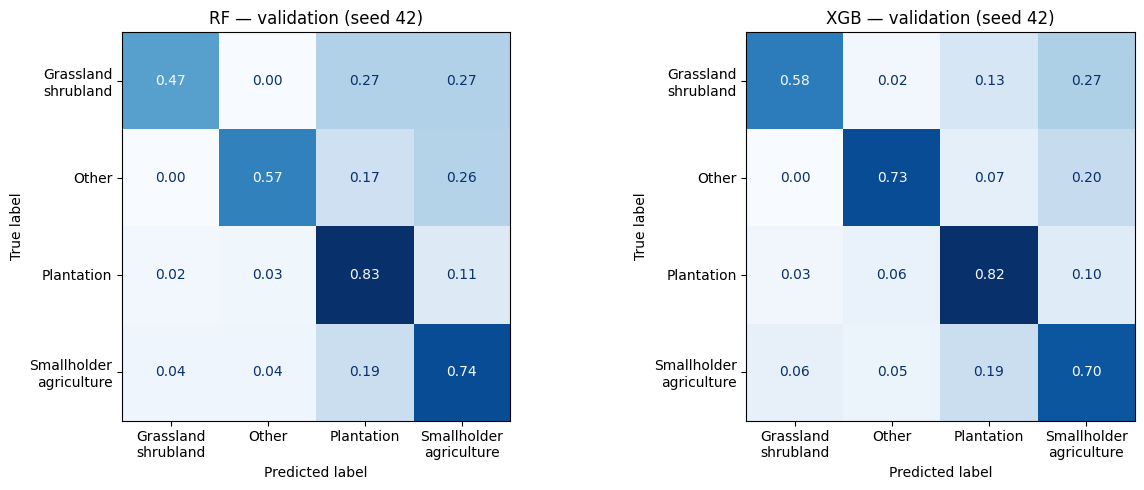

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, kind in zip(axes, ["RF", "XGB"]):
    cm = confusion_matrix(y_va, final_preds[kind], labels=range(len(CLASSES)), normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=[c.replace(" ", "\n") for c in CLASSES]).plot(
        ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(f"{kind} — validation (seed {SEED})")
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_matrices.png", dpi=150); plt.show()

## 13. Which features did the best model rely on?
**Permutation importance on validation:** shuffle one feature at a time and measure how much macro-F1 drops.
A big drop = the model depends on that feature. (More reliable than the built-in impurity importance.)

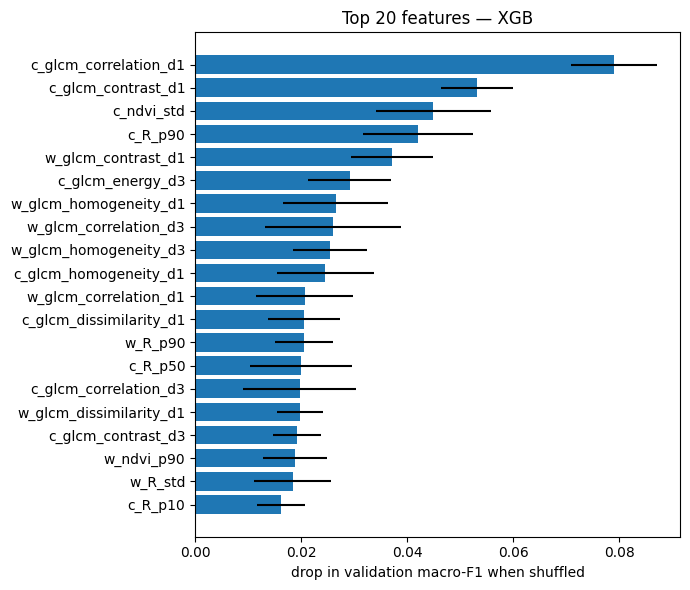

group   region     
colour  centre crop    0.2047
        whole image    0.1346
glcm    centre crop    0.2805
        whole image    0.1756
ndvi    centre crop    0.1052
        whole image    0.0746
Name: importance, dtype: float64

In [ ]:
best_kind = summary[("macro_f1", "mean")].idxmax()
pi = permutation_importance(final_models[best_kind], X_va, y_va, scoring="f1_macro",
                            n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature": FEATURES, "importance": pi.importances_mean, "std": pi.importances_std}) \
        .sort_values("importance", ascending=False)
imp.to_csv(OUT_DIR / f"permutation_importance_{best_kind}.csv", index=False)
top = imp.head(20).iloc[::-1]
plt.figure(figsize=(7, 6)); plt.barh(top["feature"], top["importance"], xerr=top["std"])
plt.xlabel("drop in validation macro-F1 when shuffled"); plt.title(f"Top 20 features — {best_kind}")
plt.tight_layout(); plt.savefig(OUT_DIR / "feature_importance.png", dpi=150); plt.show()

group = imp.assign(group=imp.feature.str.extract(r"_(glcm|ndvi|R|G|B)")[0].replace({"R": "colour", "G": "colour", "B": "colour"}),
                   region=imp.feature.str[0].map({"w": "whole image", "c": "centre crop"}))
display(group.groupby(["group", "region"])["importance"].sum().round(4))

## 14. Save models and results for later stages



In [ ]:
for kind, model in final_models.items():
    joblib.dump(model, OUT_DIR / f"best_{kind}_seed{SEED}.joblib")
results = {"features": FEATURES, "nir_channel": NIR_CH, "crop": CROP, "best_params": best,
           "majority_val": m_dummy, "n_configs": {"RF": len(rf_configs), "XGB": len(xgb_configs)},
           "manifest_sha256": meta["manifest_sha256"], "versions": {"sklearn": sklearn.__version__,
           "xgboost": xgboost.__version__, "skimage": skimage.__version__},
           "created": time.strftime("%Y-%m-%d %H:%M:%S")}
json.dump(results, open(OUT_DIR / "stage2_results.json", "w"), indent=2, default=str)
print("Saved to", OUT_DIR)

Saved to /content/drive/MyDrive/forestnet_project/outputs/stage2


## 15. Summary

In [ ]:
print("=== STAGE 2 SUMMARY ===")
print("NIR channel:", NIR_CH, "| median NDVI (sample) 10/50/90:", np.percentile(nd_medians, [10, 50, 90]).round(3))
print("Features:", len(FEATURES), "| configs: RF", len(rf_configs), "XGB", len(xgb_configs))
print("Failed runs:", int((pd.read_csv(LOG_PATH).query("stage == 2 or stage == '2'")["outcome"] == "failed").sum()))
print("Best params:", json.dumps(best, default=str))
display(table)
print("Most important feature groups (", best_kind, "):")
display(group.groupby(["group", "region"])["importance"].sum().round(4))

=== STAGE 2 SUMMARY ===
NIR channel: 0 | median NDVI (sample) 10/50/90: [0.456 0.642 0.751]
Features: 68 | configs: RF 24 XGB 40
Failed runs: 0
Best params: {"RF": {"n_estimators": 500, "max_depth": 20, "max_features": 0.3, "min_samples_leaf": 3}, "XGB": {"n_estimators": 555, "max_depth": 6, "learning_rate": 0.20481, "subsample": 0.8676, "colsample_bytree": 0.92816, "min_child_weight": 1, "gamma": 0.80902, "reg_lambda": 3.72119}}


,macro_f1,accuracy,recall_plantation,recall_other,recall_smallholder,recall_grassland,rate_P_to_S,rate_O_to_SG,train_s,infer_ms
Majority class,0.158,0.461,1.000,0.000,0.000,0.000,0.000,0.000,—,—
Random Forest,0.676 ± 0.006,0.729 ± 0.006,0.827 ± 0.010,0.581 ± 0.008,0.738 ± 0.004,0.459 ± 0.013,0.109 ± 0.003,0.257 ± 0.000,16.106 ± 6.986,0.295 ± 0.002
XGBoost,0.682 ± 0.025,0.728 ± 0.019,0.809 ± 0.012,0.657 ± 0.062,0.698 ± 0.018,0.541 ± 0.034,0.099 ± 0.003,0.229 ± 0.038,3.167 ± 0.658,0.019 ± 0.000


Most important feature groups ( XGB ):


group   region     
colour  centre crop    0.2047
        whole image    0.1346
glcm    centre crop    0.2805
        whole image    0.1756
ndvi    centre crop    0.1052
        whole image    0.0746
Name: importance, dtype: float64